In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Library berhasil disiapkan!")

Library berhasil disiapkan!


In [2]:
np.random.seed(42)

jumlah_data = 500

produk_list = ["Laptop", "Mouse", "Keyboard", "Monitor", "Headset"]
kategori_produk = {
    "Laptop": "Elektronik",
    "Mouse": "Aksesori",
    "Keyboard": "Aksesori",
    "Monitor": "Elektronik",
    "Headset": "Aksesori"
}
harga_produk = {
    "Laptop": 7500000,
    "Mouse": 150000,
    "Keyboard": 300000,
    "Monitor": 1800000,
    "Headset": 450000
}

tanggal = pd.date_range(
    start="2026-01-01",
    periods=jumlah_data,
    freq="D"
)

produk = np.random.choice(produk_list, jumlah_data)

df = pd.DataFrame({
    "tanggal": tanggal,
    "produk": produk,
    "kategori": [kategori_produk[p] for p in produk],
    "harga_satuan": [harga_produk[p] for p in produk],
    "jumlah_terjual": np.random.randint(1, 15, jumlah_data)
})

df["total_penjualan"] = (
    df["harga_satuan"] * df["jumlah_terjual"]
)

display(df.head(10))
print("Jumlah data:", len(df))

,tanggal,produk,kategori,harga_satuan,jumlah_terjual,total_penjualan
0,2026-01-01,Monitor,Elektronik,1800000,14,25200000
1,2026-01-02,Headset,Aksesori,450000,4,1800000
2,2026-01-03,Keyboard,Aksesori,300000,9,2700000
3,2026-01-04,Headset,Aksesori,450000,6,2700000
4,2026-01-05,Headset,Aksesori,450000,13,5850000
5,2026-01-06,Mouse,Aksesori,150000,11,1650000
6,2026-01-07,Keyboard,Aksesori,300000,3,900000
7,2026-01-08,Keyboard,Aksesori,300000,1,300000
8,2026-01-09,Keyboard,Aksesori,300000,4,1200000
9,2026-01-10,Headset,Aksesori,450000,12,5400000


Jumlah data: 500


In [3]:
print("Ukuran dataset:", df.shape)

print("\nInformasi dataset:")
df.info()

print("\nJumlah data kosong:")
display(df.isnull().sum())

print("\nStatistik deskriptif:")
display(df.describe().round(2))

print("\nTotal penjualan:")
print(f"Rp{df['total_penjualan'].sum():,.0f}")

Ukuran dataset: (500, 6)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   tanggal          500 non-null    datetime64[ns]
 1   produk           500 non-null    object        
 2   kategori         500 non-null    object        
 3   harga_satuan     500 non-null    int64         
 4   jumlah_terjual   500 non-null    int64         
 5   total_penjualan  500 non-null    int64         
dtypes: datetime64[ns](1), int64(3), object(2)
memory usage: 23.6+ KB

Jumlah data kosong:


,0
tanggal,0
produk,0
kategori,0
harga_satuan,0
jumlah_terjual,0
total_penjualan,0



Statistik deskriptif:


,tanggal,harga_satuan,jumlah_terjual,total_penjualan
count,500,500.00,500.00,5.000000e+02
mean,2026-09-07 12:00:00,2205000.00,7.46,1.621710e+07
min,2026-01-01 00:00:00,150000.00,1.00,1.500000e+05
25%,2026-05-05 18:00:00,300000.00,4.00,1.650000e+06
50%,2026-09-07 12:00:00,450000.00,7.00,3.900000e+06
75%,2027-01-10 06:00:00,1800000.00,11.00,1.665000e+07
max,2027-05-15 00:00:00,7500000.00,14.00,1.050000e+08
std,NaN,2863731.29,4.03,2.595810e+07



Total penjualan:
Rp8,108,550,000


,jumlah_terjual,total_penjualan
produk,,
Laptop,804,6030000000
Monitor,802,1443600000
Headset,718,323100000
Keyboard,672,201600000
Mouse,735,110250000


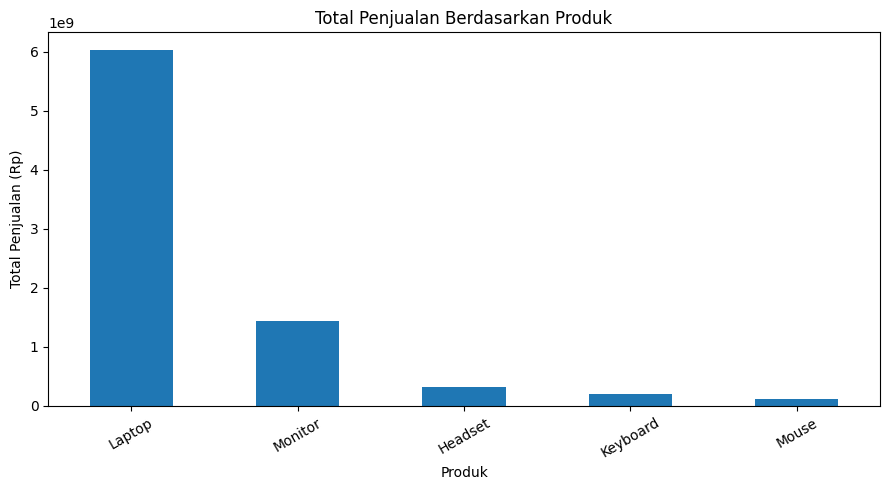

In [4]:
analisis_produk = df.groupby("produk").agg(
    jumlah_terjual=("jumlah_terjual", "sum"),
    total_penjualan=("total_penjualan", "sum")
).sort_values("total_penjualan", ascending=False)

display(analisis_produk)

plt.figure(figsize=(9, 5))
analisis_produk["total_penjualan"].plot(kind="bar")

plt.title("Total Penjualan Berdasarkan Produk")
plt.xlabel("Produk")
plt.ylabel("Total Penjualan (Rp)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

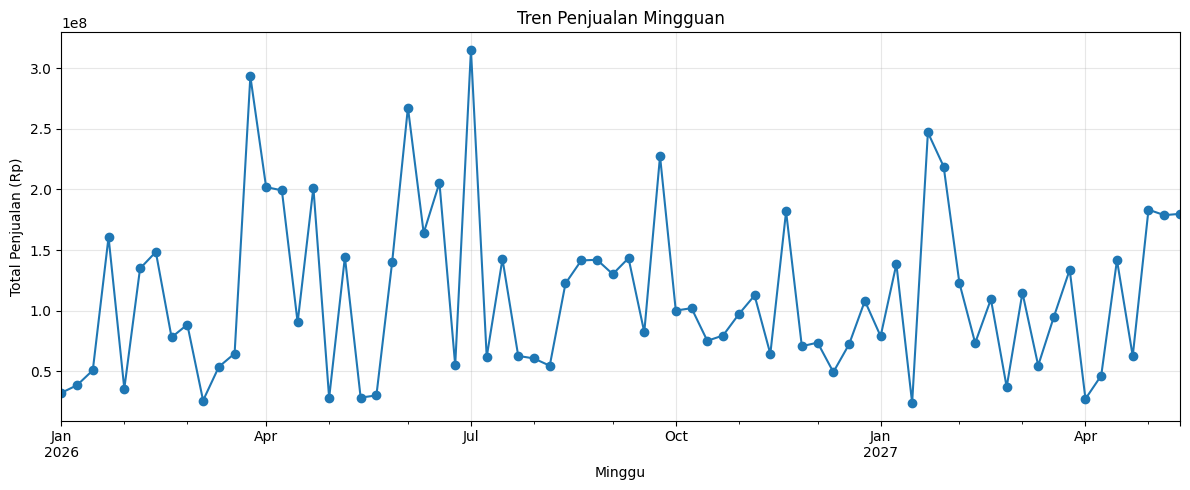

Rata-rata penjualan mingguan:
Rp112,618,750


In [5]:
penjualan_harian = df.groupby("tanggal")[
    "total_penjualan"
].sum()

penjualan_mingguan = penjualan_harian.resample("W").sum()

plt.figure(figsize=(12, 5))
penjualan_mingguan.plot(marker="o")

plt.title("Tren Penjualan Mingguan")
plt.xlabel("Minggu")
plt.ylabel("Total Penjualan (Rp)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Rata-rata penjualan mingguan:")
print(f"Rp{penjualan_mingguan.mean():,.0f}")

,total_penjualan
kategori,
Elektronik,7473600000
Aksesori,634950000


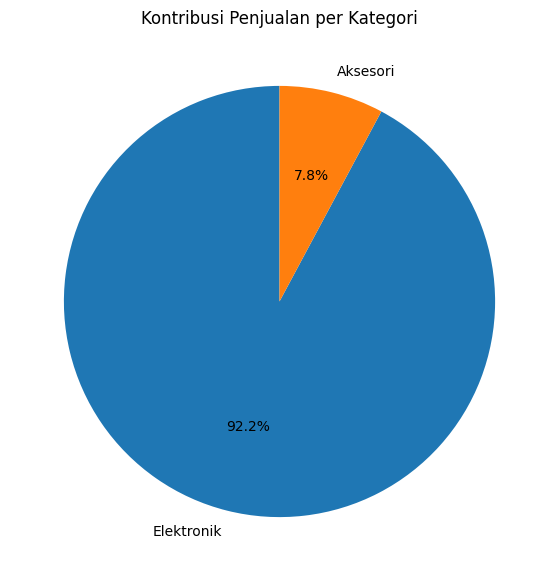

In [6]:
penjualan_kategori = df.groupby("kategori")[
    "total_penjualan"
].sum().sort_values(ascending=False)

display(penjualan_kategori)

plt.figure(figsize=(7, 7))
penjualan_kategori.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Kontribusi Penjualan per Kategori")
plt.ylabel("")
plt.show()

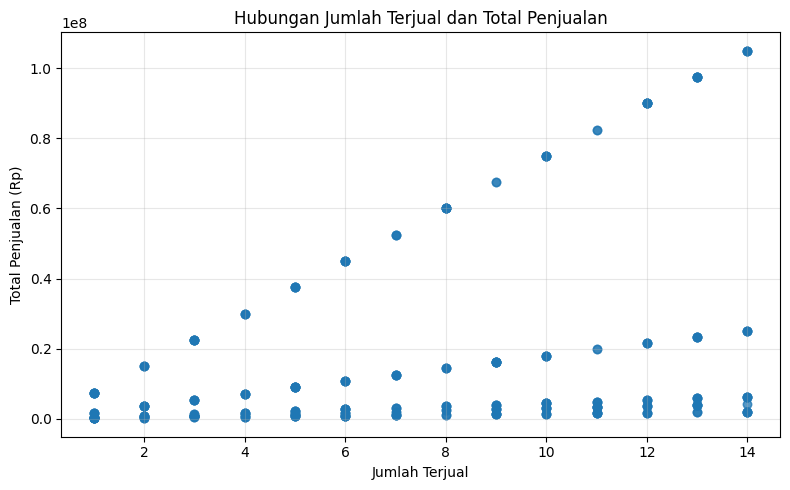

Korelasi: 0.344


In [7]:
korelasi = df["jumlah_terjual"].corr(
    df["total_penjualan"]
)

plt.figure(figsize=(8, 5))
plt.scatter(
    df["jumlah_terjual"],
    df["total_penjualan"],
    alpha=0.5
)

plt.title("Hubungan Jumlah Terjual dan Total Penjualan")
plt.xlabel("Jumlah Terjual")
plt.ylabel("Total Penjualan (Rp)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Korelasi: {korelasi:.3f}")

In [8]:
produk_terlaris = analisis_produk["jumlah_terjual"].idxmax()
produk_pendapatan = analisis_produk["total_penjualan"].idxmax()
kategori_teratas = penjualan_kategori.idxmax()

rata_penjualan = df["total_penjualan"].mean()
minggu_terakhir = penjualan_mingguan.iloc[-1]
minggu_sebelumnya = penjualan_mingguan.iloc[-2]

perubahan_mingguan = (
    (minggu_terakhir - minggu_sebelumnya)
    / minggu_sebelumnya * 100
)

print("===== INSIGHT DAN REKOMENDASI =====")
print(f"Produk dengan jumlah terjual terbanyak: {produk_terlaris}")
print(f"Produk dengan pendapatan tertinggi: {produk_pendapatan}")
print(f"Kategori dengan pendapatan tertinggi: {kategori_teratas}")

if perubahan_mingguan > 0:
    print(
        f"Penjualan mingguan terakhir naik "
        f"{perubahan_mingguan:.2f}% dibanding minggu sebelumnya."
    )
elif perubahan_mingguan < 0:
    print(
        f"Penjualan mingguan terakhir turun "
        f"{abs(perubahan_mingguan):.2f}% dibanding minggu sebelumnya."
    )
else:
    print("Penjualan mingguan terakhir tidak berubah.")

if analisis_produk["jumlah_terjual"].idxmax() == produk_pendapatan:
    print("Rekomendasi: evaluasi stok produk terlaris untuk menjaga ketersediaan.")
else:
    print("Rekomendasi: evaluasi produk berpendapatan tinggi dan produk bervolume tinggi secara terpisah.")

print("Gunakan hasil analisis sebagai bahan pertimbangan, bukan keputusan otomatis.")

===== INSIGHT DAN REKOMENDASI =====
Produk dengan jumlah terjual terbanyak: Laptop
Produk dengan pendapatan tertinggi: Laptop
Kategori dengan pendapatan tertinggi: Elektronik
Penjualan mingguan terakhir naik 0.59% dibanding minggu sebelumnya.
Rekomendasi: evaluasi stok produk terlaris untuk menjaga ketersediaan.
Gunakan hasil analisis sebagai bahan pertimbangan, bukan keputusan otomatis.


In [9]:
print("===== RINGKASAN ANALISIS DATA =====")
print(f"Jumlah transaksi simulasi: {len(df)}")
print(f"Total unit terjual: {df['jumlah_terjual'].sum()}")
print(f"Total pendapatan simulasi: Rp{df['total_penjualan'].sum():,.0f}")
print(f"Rata-rata pendapatan per baris: Rp{rata_penjualan:,.0f}")
print(f"Produk terlaris berdasarkan unit: {produk_terlaris}")
print(f"Produk dengan pendapatan tertinggi: {produk_pendapatan}")
print(f"Kategori dengan pendapatan tertinggi: {kategori_teratas}")

===== RINGKASAN ANALISIS DATA =====
Jumlah transaksi simulasi: 500
Total unit terjual: 3731
Total pendapatan simulasi: Rp8,108,550,000
Rata-rata pendapatan per baris: Rp16,217,100
Produk terlaris berdasarkan unit: Laptop
Produk dengan pendapatan tertinggi: Laptop
Kategori dengan pendapatan tertinggi: Elektronik
